In [3]:
from google.colab import files

uploaded = files.upload()

Saving bank-full.csv to bank-full.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (45211, 17)

Column names:
Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null

In [6]:
# Check duplicate records
print("Duplicates:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print(df.isnull().sum())

# Check the target column
print(df["y"].value_counts())

Duplicates: 0
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
y
no     39922
yes     5289
Name: count, dtype: int64


y
no     39922
yes     5289
Name: count, dtype: int64


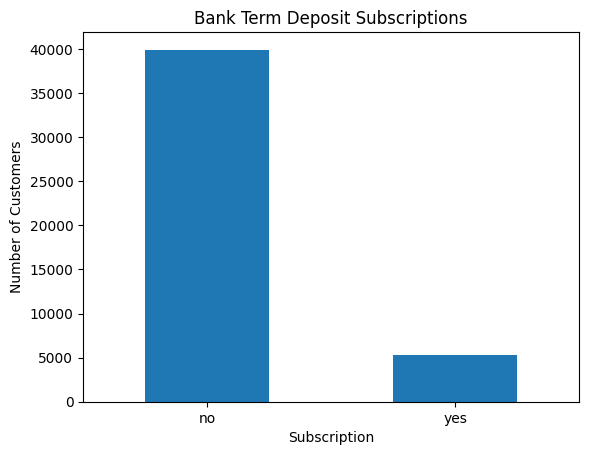

In [7]:
subscription_counts = df["y"].value_counts()

print(subscription_counts)

subscription_counts.plot(
    kind="bar",
    title="Bank Term Deposit Subscriptions"
)

plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [11]:
# Separate input features and target
X = df.drop(columns=["y", "duration"])

y = df["y"].map({"no": 0, "yes": 1})

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Preprocess numerical data
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical data
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Create the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 36168
Testing records: 9043


In [13]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [14]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Subscription", "Subscription"]
))

Model Accuracy: 89.33 %

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.66      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043



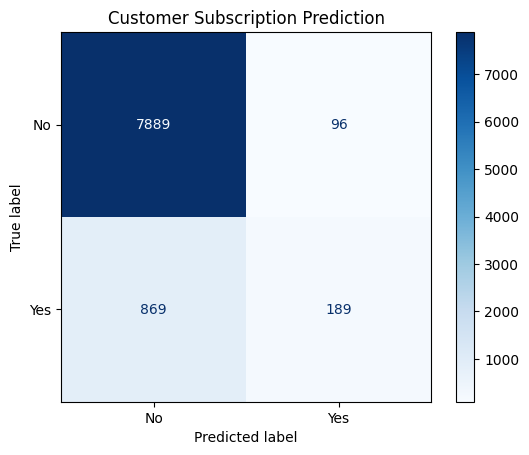

In [15]:
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Customer Subscription Prediction")
plt.show()

In [16]:
results = pd.DataFrame({
    "Actual_Subscription": y_test.map({
        0: "no",
        1: "yes"
    }),
    "Predicted_Subscription": pd.Series(
        y_pred,
        index=y_test.index
    ).map({
        0: "no",
        1: "yes"
    })
})

results.to_csv(
    "bank_marketing_predictions.csv",
    index=False
)

print("Prediction results saved!")

Prediction results saved!


In [17]:
from google.colab import files

files.download("bank_marketing_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
from sklearn.metrics import accuracy_score, classification_report

# Predict results
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed evaluation
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Subscription", "Subscription"]
    )
)

Model Accuracy: 89.33 %

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.66      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043



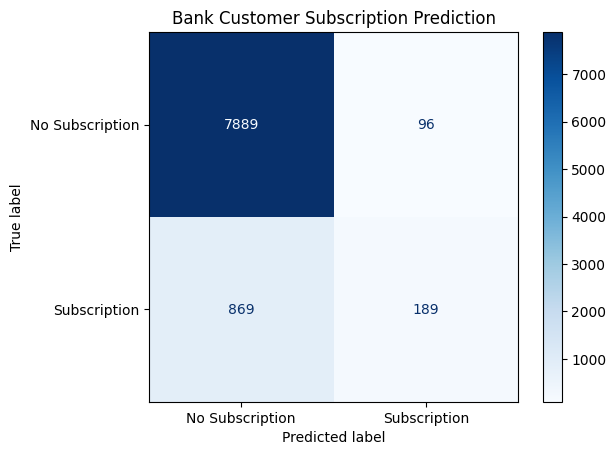

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Subscription", "Subscription"],
    cmap="Blues"
)

plt.title("Bank Customer Subscription Prediction")
plt.show()

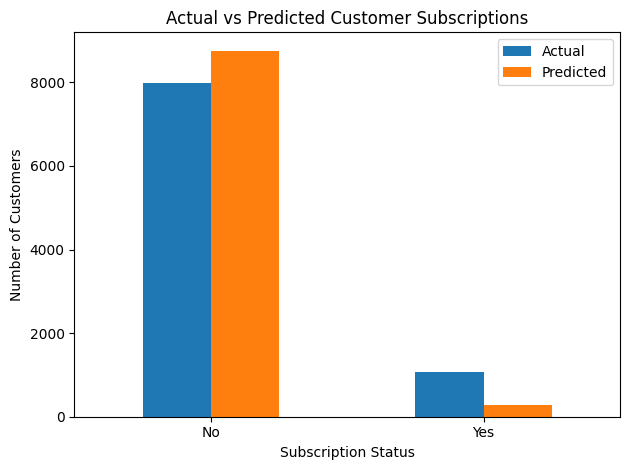

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Actual": y_test.map({0: "No", 1: "Yes"}),
    "Predicted": pd.Series(
        y_pred, index=y_test.index
    ).map({0: "No", 1: "Yes"})
})

comparison = pd.DataFrame({
    "Actual": results["Actual"].value_counts(),
    "Predicted": results["Predicted"].value_counts()
}).fillna(0)

comparison.plot(kind="bar")

plt.title("Actual vs Predicted Customer Subscriptions")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()